In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report
from imblearn.over_sampling import SMOTE
from sklearn import svm

In [236]:
df=pd.read_csv('final_raw_data.csv')

In [237]:
df

,Unnamed: 0,countv,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,...,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_10,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count,timestamp
0,0,180.0,19.699111,0.395877,0.916357,0.484293,0.000440,0.580000,-0.680889,-0.450149,...,1.698832,2.393085,0.302777,0.411111,0.488889,0.400000,0.388889,0.455556,12.0,2019-11-06 12:00:00
1,1,180.0,20.202778,0.359069,-0.584491,-0.410361,-0.000985,0.370000,-0.570000,-1.430151,...,1.832337,6.840019,0.236041,0.011111,0.466667,0.216667,0.294444,0.388889,2.0,2019-11-06 13:00:00
2,2,180.0,20.311944,0.292424,0.268199,-0.593693,0.000400,0.631944,-0.220000,3.403660,...,0.907203,1.296685,0.280246,0.377778,0.388889,0.400000,0.200000,0.411111,8.0,2019-11-06 14:00:00
3,3,180.0,19.517598,0.250620,0.781560,1.287922,-0.001013,0.310000,-0.842402,-6.361384,...,0.534580,-0.063360,0.262780,0.472222,0.133333,0.322222,0.050000,0.311111,9.0,2019-11-06 15:00:00
4,6,180.0,24.203611,0.276077,0.104541,-0.706487,0.003576,0.270000,-0.756389,-3.630974,...,0.784674,0.302181,0.259938,0.300000,0.405556,0.244444,0.488889,0.366667,10.0,2019-11-06 18:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1919,2695,180.0,20.275222,0.147046,0.983076,-0.149997,-0.000138,0.200000,-0.314778,-3.965285,...,0.538462,0.298898,0.241917,0.233333,0.216667,0.300000,0.355556,0.411111,0.0,2021-02-12 11:00:00
1920,2696,180.0,20.341500,0.175595,0.160667,-1.586928,-0.001381,0.231500,-0.040000,8.787209,...,0.456496,-0.430699,0.260747,0.294444,0.394444,0.155556,0.405556,0.194444,0.0,2021-02-12 12:00:00
1921,2697,180.0,20.396167,0.169853,-0.587861,-1.304454,0.001590,0.080000,-0.103833,-0.613238,...,0.941889,2.041977,0.267992,0.366667,0.416667,0.255556,0.055556,0.277778,0.0,2021-02-12 13:00:00
1922,2698,180.0,20.337611,0.126663,0.145635,-0.516164,-0.000902,0.090000,-0.252389,-4.362070,...,1.696733,4.097968,0.279384,0.416667,0.333333,0.433333,0.027778,0.372222,0.0,2021-02-12 14:00:00


In [238]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [239]:
df['move_type'].value_counts()

2    957
1    530
0    437
Name: move_type, dtype: int64

In [240]:
del df['Unnamed: 0']

In [241]:
del df['countv']

In [242]:
drop_features = ['total_count','move_type','timestamp']
target_feature = 'move_type'

In [243]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [244]:
X

,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,temperature_xt_jerk_5,temperature_xt_jerk_6,...,COValue_tm_dom_25,COValue_xf_jerk_2,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_10,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
0,19.699111,0.395877,0.916357,0.484293,0.000440,0.580000,-0.680889,-0.450149,14.422581,0.025,...,0.093923,0.250748,1.698832,2.393085,0.302777,0.411111,0.488889,0.400000,0.388889,0.455556
1,20.202778,0.359069,-0.584491,-0.410361,-0.000985,0.370000,-0.570000,-1.430151,14.727440,0.030,...,0.082873,0.731154,1.832337,6.840019,0.236041,0.011111,0.466667,0.216667,0.294444,0.388889
2,20.311944,0.292424,0.268199,-0.593693,0.000400,0.631944,-0.220000,3.403660,26.214403,0.030,...,0.143646,0.839343,0.907203,1.296685,0.280246,0.377778,0.388889,0.400000,0.200000,0.411111
3,19.517598,0.250620,0.781560,1.287922,-0.001013,0.310000,-0.842402,-6.361384,68.310065,0.000,...,0.088398,1.284916,0.534580,-0.063360,0.262780,0.472222,0.133333,0.322222,0.050000,0.311111
4,24.203611,0.276077,0.104541,-0.706487,0.003576,0.270000,-0.756389,-3.630974,29.724334,0.020,...,0.132597,0.226071,0.784674,0.302181,0.259938,0.300000,0.405556,0.244444,0.488889,0.366667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1919,20.275222,0.147046,0.983076,-0.149997,-0.000138,0.200000,-0.314778,-3.965285,54.810323,0.000,...,0.082873,1.310984,0.538462,0.298898,0.241917,0.233333,0.216667,0.300000,0.355556,0.411111
1920,20.341500,0.175595,0.160667,-1.586928,-0.001381,0.231500,-0.040000,8.787209,101.700716,0.000,...,0.082873,0.866868,0.456496,-0.430699,0.260747,0.294444,0.394444,0.155556,0.405556,0.194444
1921,20.396167,0.169853,-0.587861,-1.304454,0.001590,0.080000,-0.103833,-0.613238,8.733483,0.000,...,0.099448,0.227582,0.941889,2.041977,0.267992,0.366667,0.416667,0.255556,0.055556,0.277778
1922,20.337611,0.126663,0.145635,-0.516164,-0.000902,0.090000,-0.252389,-4.362070,34.134028,0.010,...,0.099448,1.174507,1.696733,4.097968,0.279384,0.416667,0.333333,0.433333,0.027778,0.372222


In [245]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.feature_selection import mutual_info_regression


# Apply Information Gain
ig = mutual_info_regression(X, y)

# Create a dictionary of feature importance scores
feature_scores = {}
for i in range(len(X.columns)):
    feature_scores[X.columns[i]] = ig[i]
# Sort the features by importance score in descending order
sorted_features = sorted(feature_scores.items(), key=lambda x: x[1], reverse=True)

# Print the feature importance scores and the sorted features
for feature, score in sorted_features:
    print("Feature:", feature, "Score:", score)

Feature: CO2CosIRValue_stat_0 Score: 0.20610676621707924
Feature: CO2MG811Value_stat_0 Score: 0.17921589549041883
Feature: temperature_xt_jerk_9 Score: 0.16890362547419002
Feature: humidity_stat_0 Score: 0.16087576888467492
Feature: MOX1_stat_0 Score: 0.16044918241210748
Feature: temperature_tm_dom_18 Score: 0.15469250086720532
Feature: temperature_stat_0 Score: 0.15230251298528952
Feature: MOX1_tm_dom_8 Score: 0.15202715672789058
Feature: humidity_xt_jerk_9 Score: 0.14199588239831762
Feature: temperature_xt_jerk_1 Score: 0.12948791370514545
Feature: humidity_xt_jerk_2 Score: 0.12692415081542396
Feature: temperature_xt_jerk_2 Score: 0.12426050416790879
Feature: MOX1_stat_3 Score: 0.12283357853844468
Feature: MOX1_tm_dom_4 Score: 0.11757668782068986
Feature: humidity_stat_3 Score: 0.11609707056711649
Feature: MOX1_tm_dom_16 Score: 0.11599229051118431
Feature: temperature_tm_dom_16 Score: 0.11318140971270552
Feature: MOX1_xt_jerk_9 Score: 0.10839463652304815
Feature: humidity_tm_dom_4 Sc

In [246]:
keep=['CO2CosIRValue_stat_0','CO2MG811Value_stat_0','temperature_xt_jerk_9','humidity_stat_0','MOX1_stat_0','temperature_tm_dom_18','MOX1_tm_dom_8','temperature_stat_0','humidity_xt_jerk_9','MOX1_stat_3','MOX1_tm_dom_4','humidity_stat_3','MOX1_tm_dom_16','temperature_xt_jerk_2','temperature_tm_dom_16','temperature_xt_jerk_1','MOX1_xt_jerk_9','humidity_tm_dom_4','MOX1_xt_jerk_2']

In [265]:
keep1=['humidity_stat_0','CO2CosIRValue_stat_0','CO2MG811Value_stat_0','temperature_stat_0','MOX1_stat_0','MOX1_tm_dom_8','temperature_xt_jerk_9','temperature_xt_jerk_1','temperature_tm_dom_18','humidity_xt_jerk_9','humidity_stat_3','temperature_tm_dom_16','temperature_xt_jerk_2','MOX1_stat_3','MOX1_tm_dom_16']

In [266]:
X=df[keep1]

In [267]:
X

,humidity_stat_0,CO2CosIRValue_stat_0,CO2MG811Value_stat_0,temperature_stat_0,MOX1_stat_0,MOX1_tm_dom_8,temperature_xt_jerk_9,temperature_xt_jerk_1,temperature_tm_dom_18,humidity_xt_jerk_9,humidity_stat_3,temperature_tm_dom_16,temperature_xt_jerk_2,MOX1_stat_3,MOX1_tm_dom_16
0,51.239833,84.727778,616.772222,19.699111,530.872222,50585.163564,1.813605,0.580000,4.992788,7.546645,0.974251,19.629285,-0.680889,4.325219,190.145271
1,49.903167,81.994444,618.461111,20.202778,427.705556,65178.862390,1.269493,0.370000,8.219864,6.732080,1.064936,25.965631,-0.570000,50.685325,3567.963362
2,50.692444,85.977778,615.988889,20.311944,385.505556,49039.396600,0.852427,0.631944,8.083606,6.718433,1.037522,21.871052,-0.220000,23.892600,1717.811132
3,53.560223,86.983240,616.396648,19.517598,409.351955,45503.057586,1.150042,0.310000,4.187562,3.971059,0.621436,7.670892,-0.842402,18.774737,487.317933
4,48.901778,105.433333,603.805556,24.203611,464.738889,43026.732646,1.147862,0.270000,8.293930,7.668455,0.826778,24.303867,-0.756389,2.092776,61.171633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1919,58.441167,43.233333,518.155556,20.275222,528.961111,48621.777048,0.140993,0.200000,2.214626,0.826477,0.389594,13.172454,-0.314778,1.331156,69.090467
1920,58.252778,42.883333,518.011111,20.341500,530.033333,48559.058207,0.044746,0.231500,1.327771,0.144371,0.253377,2.661725,-0.040000,0.957090,37.703437
1921,57.806222,42.988889,518.072222,20.396167,530.455556,48658.496573,0.057491,0.080000,0.816131,0.252525,0.266046,2.645056,-0.103833,1.249629,48.929507
1922,57.908111,43.650000,518.077778,20.337611,529.527778,48769.766611,0.122300,0.090000,2.673492,0.665958,0.294849,4.190032,-0.252389,1.404140,57.991448


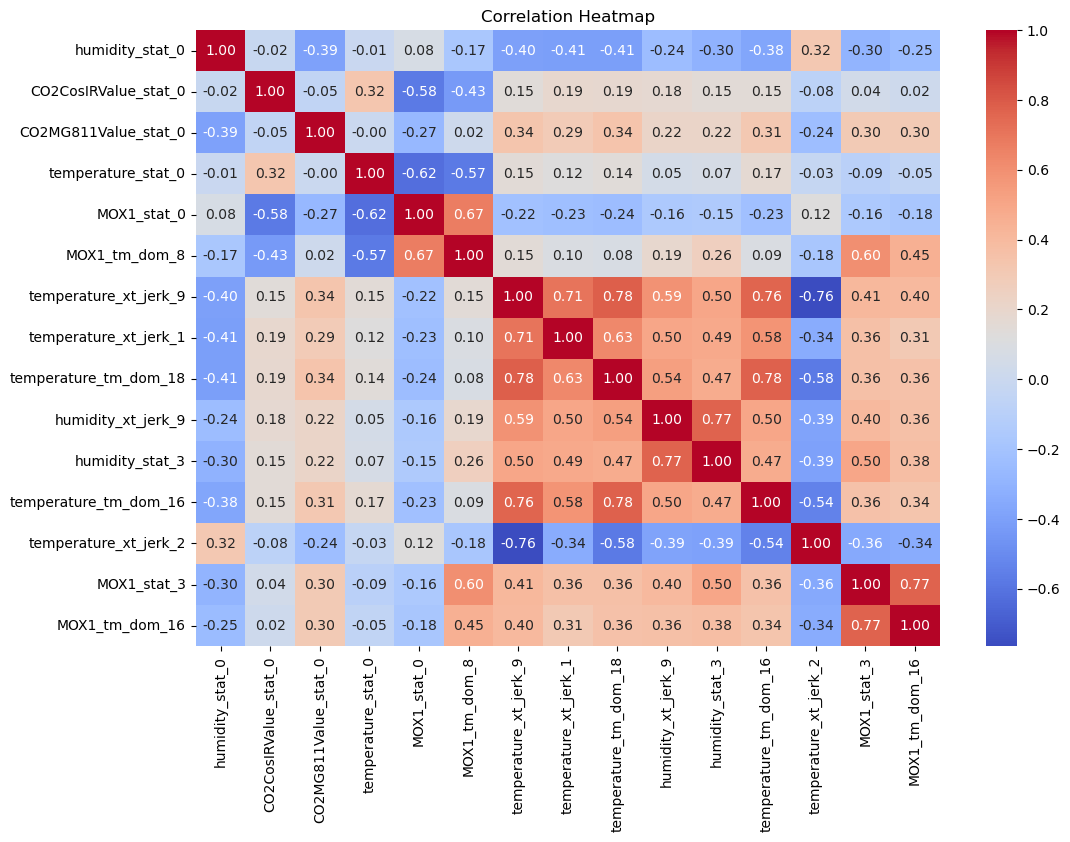

In [268]:
import seaborn as sns
correlation_matrix = X.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [269]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=345)

In [270]:
model1 = LogisticRegression(max_iter=1000,multi_class='ovr', random_state=2,C=10,penalty='l2',solver='newton-cg')
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/utils/optimize.py:203: UserWarning: Line Search failed
  warnings.warn("Line Search failed")
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:416: LineSearchWarning: Rounding errors prevent the line search from converging
  warn(msg, LineSearchWarning)


In [271]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.73
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.90      0.85       108
           1       0.60      0.30      0.40       116
           2       0.72      0.85      0.78       257

    accuracy                           0.73       481
   macro avg       0.71      0.68      0.68       481
weighted avg       0.71      0.73      0.70       481



In [278]:
model2 = DecisionTreeClassifier(max_depth=5,splitter='best')
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [279]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.69
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.77      0.81       108
           1       0.48      0.42      0.45       116
           2       0.71      0.78      0.74       257

    accuracy                           0.69       481
   macro avg       0.68      0.66      0.67       481
weighted avg       0.69      0.69      0.69       481



In [291]:
model3 = RandomForestClassifier(n_estimators=200,max_depth=5)
model3.fit(X_train, y_train)

# Make predictions
y_pred = model3.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

Accuracy: 0.762993762993763
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.84      0.85       108
           1       0.73      0.38      0.50       116
           2       0.73      0.90      0.81       257

    accuracy                           0.76       481
   macro avg       0.78      0.71      0.72       481
weighted avg       0.76      0.76      0.75       481



In [168]:
scores=[]
for i in range(1000):
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model3 = RandomForestClassifier(n_estimators=250,max_depth=5)
    model3.fit(X_train, y_train)
    # Make predictions
    y_pred = model3.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))

In [262]:
from sklearn.ensemble import ExtraTreesClassifier
import matplotlib.pyplot as plt
model = ExtraTreesClassifier()
model.fit(X,y)

ExtraTreesClassifier()

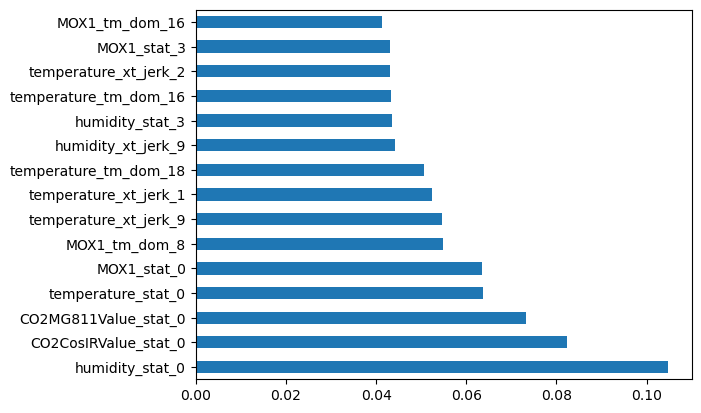

In [263]:
#plot graph of feature importances for better visualization
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
feat_importances.nlargest(15).plot(kind='barh')
plt.show()

In [264]:
feat_importances.nlargest(15)

humidity_stat_0          0.104792
CO2CosIRValue_stat_0     0.082361
CO2MG811Value_stat_0     0.073199
temperature_stat_0       0.063756
MOX1_stat_0              0.063384
MOX1_tm_dom_8            0.054793
temperature_xt_jerk_9    0.054656
temperature_xt_jerk_1    0.052354
temperature_tm_dom_18    0.050575
humidity_xt_jerk_9       0.044128
humidity_stat_3          0.043611
temperature_tm_dom_16    0.043211
temperature_xt_jerk_2    0.043025
MOX1_stat_3              0.042979
MOX1_tm_dom_16           0.041385
dtype: float64

In [169]:
top_5_indices = np.argsort(scores)[-5:][::-1]

print("Indices of top 5 scores:", top_5_indices)
print("Top 5 scores:", [scores[i] for i in top_5_indices])

Indices of top 5 scores: [345 747 135 322 486]
Top 5 scores: [0.7713097713097713, 0.7692307692307693, 0.7650727650727651, 0.760914760914761, 0.7567567567567568]


In [171]:
np.mean(scores)

0.712037422037422

In [174]:
score1=[]
for i in [345,747,135]:
    X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=i)
    model3 = RandomForestClassifier(n_estimators=250,max_depth=5)
    model3.fit(X_train, y_train)
    # Make predictions
    y_pred = model3.predict(X_test)
    score1.append(accuracy_score(y_test, y_pred))
np.mean(score1)

0.7616077616077616

In [199]:
random_states = [345, 747, 135]
scores = []
confusion_matrices = []
classification_reports = []

for i in random_states:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=i)
    model = RandomForestClassifier(n_estimators=250, max_depth=5)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    scores.append(accuracy_score(y_test, y_pred))
    confusion_matrices.append(confusion_matrix(y_test, y_pred))
    classification_reports.append(classification_report(y_test, y_pred))

mean_accuracy = np.mean(scores)
print(f'Mean Accuracy: {mean_accuracy}')

# Displaying the confusion matrices and classification reports
for idx, state in enumerate(random_states):
    print(f'\nRandom State: {state}')
    print(f'Confusion Matrix:\n{confusion_matrices[idx]}')
    print(f'Classification Report:\n{classification_reports[idx]}')

Mean Accuracy: 0.7602217602217602

Random State: 345
Confusion Matrix:
[[ 90   0  18]
 [  4  46  66]
 [  9  17 231]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       108
           1       0.73      0.40      0.51       116
           2       0.73      0.90      0.81       257

    accuracy                           0.76       481
   macro avg       0.78      0.71      0.72       481
weighted avg       0.76      0.76      0.75       481


Random State: 747
Confusion Matrix:
[[ 89   1  21]
 [  3  54  59]
 [  9  21 224]]
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.84       111
           1       0.71      0.47      0.56       116
           2       0.74      0.88      0.80       254

    accuracy                           0.76       481
   macro avg       0.78      0.72      0.73       481
weighted avg       0.76      0.76      0.75    

In [201]:
y

0       2
1       1
2       2
3       2
4       2
       ..
1919    0
1920    0
1921    0
1922    0
1923    0
Name: move_type, Length: 1924, dtype: int64

In [80]:
from sklearn.metrics import f1_score

In [85]:
rbf = svm.SVC(kernel='sigmoid', gamma=0.1, C=10).fit(X_train, y_train)
poly = svm.SVC(kernel='poly', degree=5, C=1).fit(X_train, y_train)

In [86]:
poly_pred = poly.predict(X_test)
rbf_pred = rbf.predict(X_test)

In [87]:
poly_accuracy = accuracy_score(y_test, poly_pred)
poly_f1 = f1_score(y_test, poly_pred, average='weighted')
print('Accuracy (Polynomial Kernel): ', "%.2f" % (poly_accuracy*100))
print('F1 (Polynomial Kernel): ', "%.2f" % (poly_f1*100))

Accuracy (Polynomial Kernel):  52.81
F1 (Polynomial Kernel):  36.50


In [88]:
rbf_accuracy = accuracy_score(y_test, rbf_pred)
rbf_f1 = f1_score(y_test, rbf_pred, average='weighted')
print('Accuracy (RBF Kernel): ', "%.2f" % (rbf_accuracy*100))
print('F1 (RBF Kernel): ', "%.2f" % (rbf_f1*100))

Accuracy (RBF Kernel):  52.81
F1 (RBF Kernel):  36.50
